In [ ]:
import os
import gc
import glob
import random
import warnings
from datetime import datetime

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import cv2

import torch
import torch.nn as nn
import torchvision.models as models
from torchvision import transforms

from PIL import Image
from PIL import Image as PILImage
from tqdm.auto import tqdm

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import preprocess_image

from lime import lime_image
import shap

import quantus
from quantus import MaxSensitivity, norm_func, similarity_func
import matplotlib.pyplot as plt


In [2]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

SEED = 42
set_seed(SEED)


In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Fixed 224x224 inputs -> let cuDNN pick the fastest conv algorithms
torch.backends.cudnn.benchmark = True

Using device: cuda


In [4]:
name = "aveera"

In [ ]:
IDRID_DIR = f"/data/{name}/Refined IDRiD"
IDRID_SPLIT_DIRS = [
    os.path.join(IDRID_DIR, "Test", "Test"),
    os.path.join(IDRID_DIR, "Train", "Train"),
]

drive_model_dir = f"/data/{name}/aptos2019-blindness-detection/new_models"
RESULTS_DIR = f"/data/{name}/results"
CHECKPOINT_DIR = f"/data/{name}/results/maxsens_checkpoints"
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

for split_dir in IDRID_SPLIT_DIRS:
    assert os.path.isdir(os.path.join(split_dir, "Images")), (
        f"Expected an 'Images' folder inside {split_dir} -- check IDRID_DIR."
    )
print(f"Using Refined IDRiD data from '{IDRID_DIR}' (Test + Train splits)")


Using Refined IDRiD data from '/data/aveera/Refined IDRiD' (Test + Train splits)


**Memory hygiene helpers**

In [ ]:
import ctypes
import resource

try:
    _libc = ctypes.CDLL("libc.so.6")
except OSError:
    _libc = None


def clear_memory():
    """Reclaim Python and CUDA memory"""
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()
    if _libc is not None:
        _libc.malloc_trim(0)


def log_rss(tag=""):
    """Log resident set size (the number SLURM's OOM killer actually watches)."""
    rss_mb = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024  
    msg = f"[rss{' ' + tag if tag else ''}] peak RSS so far = {rss_mb:.0f} MB"
    if torch.cuda.is_available():
        msg += f"  |  GPU allocated = {torch.cuda.memory_allocated()/1e6:.0f} MB"
    print(msg)


def unload_model(model=None, engine=None, engine_cache=None):
    """Fully detach a model + its AttributionEngine from memory before loading the next one."""
    if engine is not None and engine_cache is not None:
        engine_cache.pop(id(model), None)
        engine._gradcam = None
        engine.shap_explainer = None
        del engine
    if model is not None:
        model.to("cpu")
        del model
    clear_memory()


def gpu_mem_report(tag=""):
    if torch.cuda.is_available():
        alloc = torch.cuda.memory_allocated() / 1e9
        reserved = torch.cuda.memory_reserved() / 1e9
        print(f"[mem{' ' + tag if tag else ''}] allocated={alloc:.2f} GB  reserved={reserved:.2f} GB")


**Loading and pre-processing Refined IDRiD**

In [7]:
# Pixel values of all lesion classes (background + anatomical structures excluded)
LESION_LABEL_IDS = {
    4,    # Vitreous Hemorrhage (VH)
    63,   # Hard Exudate (EX)
    96,   # IRMA
    127,  # Hemorrhage (HE)
    166,  # Neovascularization (NV)
    191,  # Cotton-Wool Spot (CWS)
    255,  # Microaneurysm (MA)
}


In [ ]:
def resize_mask_no_loss(mask, target_size):
    mask_f = mask.astype(np.float32)
    coverage = cv2.resize(mask_f, target_size, interpolation=cv2.INTER_AREA)
    # any nonzero coverage in the box -> lesion touched that region
    return (coverage > 0).astype(np.uint8)

def load_and_preprocess(split_dirs, target_size=(224, 224), max_images=None):

    samples = []
    for split_dir in split_dirs:
        images_dir = os.path.join(split_dir, "Images")
        labels_dir = os.path.join(split_dir, "Labels")

        image_paths = sorted(glob.glob(os.path.join(images_dir, "*.jpg")))
        for img_path in image_paths:
            if split_dir == os.path.normpath("/data/aveera/Refined IDRiD/Train/Train"): 
              image_id = os.path.splitext(os.path.basename(img_path))[0]+"_vessel"
            else:
              image_id = os.path.splitext(os.path.basename(img_path))[0] 

            mask_path = os.path.join(labels_dir, f"{image_id}.png")
            if not os.path.isfile(mask_path):
                continue

            raw_mask = np.array(Image.open(mask_path).convert('L'))
            raw_img = np.array(Image.open(img_path).convert('RGB'))

            # Resizes the lesion mask if the height and width aren't the same as the original image
            if raw_mask.shape[:2] != raw_img.shape[:2]:
                raw_mask = cv2.resize(raw_mask, (raw_img.shape[1], raw_img.shape[0]),interpolation=cv2.INTER_NEAREST)

            green_channel = raw_img[:, :, 1] 

            clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
            enhanced_green = clahe.apply(green_channel) 

            rgb_enhanced = cv2.merge([enhanced_green, enhanced_green, enhanced_green]) # Merge into a clean 3-channel layout 

            img_resized = cv2.resize(rgb_enhanced, (224, 224), interpolation=cv2.INTER_CUBIC)# Resize the image

            # Keep only lesion pixels and exclude background and the 4 anatomical classes
            lesion_mask = np.isin(raw_mask, list(LESION_LABEL_IDS)).astype(np.uint8)

            mask_resized = resize_mask_no_loss(lesion_mask, target_size)

            samples.append((img_resized, mask_resized))

            if max_images is not None and len(samples) >= max_images:
                return samples
        print("There are ", len(samples)," images in ", split_dir)

    return samples

In [ ]:
# MaxSensitivity only needs the first N_TEST samples (same value as the original notebook),
# so we cap the load here instead of loading every split image into RAM.
N_TEST = 81

idrid_subset = load_and_preprocess(IDRID_SPLIT_DIRS, max_images=N_TEST)
print(f"Loaded {len(idrid_subset)} IDRiD images (capped at N_TEST={N_TEST})")

maxsens_samples = idrid_subset[:N_TEST]


There are  27  images in  /data/aveera/Refined IDRiD/Test/Test


Loaded 81 IDRiD images (capped at N_TEST=81)


**Model loading**

In [10]:
def load_model(model_name, weight_path, device):
    if model_name == "resnet50":
        model = models.resnet50(weights=None)
        num_features = model.fc.in_features
        model.fc = nn.Sequential(nn.Dropout(0.4), nn.Linear(num_features, 5))
    elif model_name == "efficientnetb0":
        model = models.efficientnet_b0(weights=None)
        num_features = model.classifier[1].in_features
        model.classifier = nn.Sequential(nn.Dropout(0.4), nn.Linear(num_features, 5))
    else:
        raise ValueError(f"Unknown model_name: {model_name}")

    model.load_state_dict(torch.load(weight_path, map_location=device))
    model = model.to(device)
    model.eval()
    return model


**Attribution engine**

In [ ]:
class AttributionEngine:
    IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
    IMAGENET_STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)
    CLASS_NAMES = ["No DR", "Mild DR", "Moderate DR", "Severe DR", "Proliferative DR"]

    def __init__(self, model, device, lime_samples=1000, img_size=224, shap_max_evals=500,
                 shap_batch_size=50, predict_chunk_size=32):
        self.model = model.to(device)
        self.model.eval()
        self.device = device

        self.lime_samples    = lime_samples
        self.img_size        = img_size
        self.shap_max_evals  = shap_max_evals
        self.shap_batch_size = shap_batch_size
        self.class_names     = self.CLASS_NAMES
        self.predict_chunk_size = predict_chunk_size

        self._gradcam = None

        self._norm_transform = transforms.Normalize(mean=self.IMAGENET_MEAN.tolist(), std=self.IMAGENET_STD.tolist())
        self.shap_explainer = None
        self.lime_explainer = lime_image.LimeImageExplainer()

    def find_gradcam_target_layer(self):
        if hasattr(self.model, "layer4"):
            target_layer = self.model.layer4[-1]
        elif hasattr(self.model, "features"):
            target_layer = self.model.features[-1]
        else:
            conv_layers = [m for m in self.model.modules() if isinstance(m, nn.Conv2d)]
            if not conv_layers:
                raise ValueError("Could not locate a Conv2d layer in the model for Grad-CAM.")
            target_layer = conv_layers[-1]
        return target_layer



    def unnormalize_to_uint8(self, img_tensor):
        img = img_tensor.detach().cpu().numpy().transpose(1, 2, 0)
        img = img * self.IMAGENET_STD + self.IMAGENET_MEAN
        img = np.clip(img, 0.0, 1.0)
        return (img * 255).astype(np.uint8)

    @staticmethod
    def normalize_map(m, pct_clip=99.0, mode="abs"):
        m = np.nan_to_num(m.astype(np.float32))
        if mode == "abs":
            m = np.abs(m)
        elif mode == "pos":
            m = np.clip(m, 0, None)
        else:
            raise ValueError(f"Unknown normalize mode: {mode!r} (expected 'abs' or 'pos')")

        if m.max() > 0:
            clip_val = np.percentile(m, pct_clip)
            if clip_val > 0:
                m = np.clip(m, 0, clip_val)
        mn, mx = m.min(), m.max()
        if mx - mn > 1e-12:
            m = (m - mn) / (mx - mn)
        else:
            m = np.zeros_like(m)
        return m

    def resize_map(self, m):
        if m.shape[0] != self.img_size or m.shape[1] != self.img_size:
            m = cv2.resize(m.astype(np.float32), (self.img_size, self.img_size), interpolation=cv2.INTER_LINEAR)
        return m

    def compute_gradcam(self, img, target_class):
        cam = self.get_gradcam()
        targets = [ClassifierOutputTarget(target_class)]
        grayscale_cam = cam(input_tensor=img, targets=targets)[0]
        heatmap = self.normalize_map(grayscale_cam, mode="abs")
        return self.resize_map(heatmap)

    def _predict_in_chunks(self, numpy_images):
        outputs = []
        n = numpy_images.shape[0]
        for start in range(0, n, self.predict_chunk_size):
            chunk = numpy_images[start:start + self.predict_chunk_size]
            tensor = torch.from_numpy(chunk).float().to(self.device)
            tensor = tensor / 255.0
            tensor = tensor.permute(0, 3, 1, 2)
            tensor = self._norm_transform(tensor)
            with torch.no_grad():
                logits = self.model(tensor)
            outputs.append(logits.cpu().numpy())
            del tensor, logits, chunk
        return np.concatenate(outputs, axis=0)

    def _lime_predict_fn(self, numpy_images):
        return self._predict_in_chunks(numpy_images)

    def compute_lime(self, raw_img_uint8, target_class):
        np.random.seed(SEED)
        random.seed(SEED)
        torch.manual_seed(SEED)

        explanation = self.lime_explainer.explain_instance(
            raw_img_uint8.astype('double'),
            self._lime_predict_fn,
            top_labels=1,
            hide_color=0,
            num_samples=self.lime_samples,
        )

        if target_class not in explanation.local_exp:
            raise ValueError(
                f"LIME did not explain class {target_class} "
                f"(only explained {list(explanation.local_exp.keys())}); increase top_labels."
            )
        return explanation

    def close_lime_explanation(self, explanation):
        explanation.segments = None
        explanation.local_exp = None
        explanation.local_pred = None

    def get_lime_heatmap(self, explanation, target_class):
        dict_heatmap = dict(explanation.local_exp[target_class])
        heatmap = np.vectorize(dict_heatmap.get)(explanation.segments)
        heatmap = self.normalize_map(heatmap, mode="pos")
        return self.resize_map(heatmap)

    def _shap_predict_fn(self, numpy_images):
        return self._predict_in_chunks(numpy_images)

    def _build_shap_explainer(self, image_shape):
        np.random.seed(SEED)
        random.seed(SEED)
        torch.manual_seed(SEED)
        masker_blur = shap.maskers.Image("blur(32,32)", image_shape)
        self.shap_explainer = shap.Explainer(self._shap_predict_fn, masker_blur, output_names=self.class_names)

    def compute_shap(self, raw_img_uint8, target_class=None, all_classes=True):
        np.random.seed(SEED)
        random.seed(SEED)
        torch.manual_seed(SEED)

        if self.shap_explainer is None:
            self._build_shap_explainer(raw_img_uint8.shape)

        images_batch = raw_img_uint8[np.newaxis, ...]
        n_classes = len(self.class_names) if self.class_names else 5
        outputs = list(range(n_classes)) if all_classes else [target_class]

        return self.shap_explainer(images_batch, max_evals=self.shap_max_evals, batch_size=self.shap_batch_size, outputs=outputs)

    def get_shap_heatmap(self, shap_values, class_position=0):
        raw_shap = shap_values.values[0, :, :, :, class_position]
        sv_signed = raw_shap.sum(axis=-1)
        heatmap = self.normalize_map(sv_signed, mode="pos")
        return self.resize_map(heatmap), self.resize_map(sv_signed)


In [12]:
_engine_cache = {}

def get_engine_for(model):
    """Look up the AttributionEngine that was built for this exact model object."""
    eng = _engine_cache.get(id(model))
    if eng is None:
        raise RuntimeError("No AttributionEngine registered for this model.")
    return eng


In [13]:
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])


def get_predicted_labels(model, samples, device, transform=test_transform):
    preds = []
    model.eval()
    with torch.no_grad():
        for raw_img_np, _ in samples:
            input_tensor = transform(PILImage.fromarray(raw_img_np)).unsqueeze(0).to(device)
            pred = model(input_tensor).argmax(dim=1).item()
            preds.append(pred)
    return np.array(preds)


**Max-sensitivity xai functions**

In [14]:
def explain_gradcam(model, inputs, targets, **kwargs):
    maps = []
    eng = get_engine_for(model)
    for img, target in zip(inputs, targets):
        img_tensor = torch.from_numpy(img).float()
        gradcam = eng.compute_gradcam(img_tensor.unsqueeze(0).to(eng.device), int(target))
        maps.append(gradcam)
    return np.stack(maps)[:, None, :, :]


def explain_lime(model, inputs, targets, **kwargs):
    maps = []
    eng = get_engine_for(model)
    for img, target in zip(inputs, targets):
        img_tensor = torch.from_numpy(img).float()
        raw = eng.unnormalize_to_uint8(img_tensor)
        explanation = eng.compute_lime(raw, int(target))
        heatmap = eng.get_lime_heatmap(explanation, int(target))
        maps.append(heatmap)
        eng.close_lime_explanation(explanation)
        del explanation
    return np.stack(maps)[:, None, :, :]


def explain_shap(model, inputs, targets, **kwargs):
    maps = []
    eng = get_engine_for(model)
    for img, target in zip(inputs, targets):
        img_tensor = torch.from_numpy(img).float()
        raw = eng.unnormalize_to_uint8(img_tensor)
        shap_values = eng.compute_shap(raw, target_class=int(target), all_classes=False)
        heatmap, _ = eng.get_shap_heatmap(shap_values, class_position=0)
        maps.append(heatmap)
    return np.stack(maps)[:, None, :, :]


# Kept as an ordered dict-of-one so we can loop "one method at a time" deliberately below
explain_funcs = {
    "GradCAM": explain_gradcam,
    "LIME": explain_lime,
    "SHAP": explain_shap,
}


**Checkpointing**

In [15]:
CHECKPOINT_PATH = os.path.join(CHECKPOINT_DIR, "maxsens_per_image_checkpoint.csv")

CHECKPOINT_COLUMNS = ["model", "method", "image_index", "max_sensitivity"]


def load_checkpoint():
    if os.path.exists(CHECKPOINT_PATH):
        return pd.read_csv(CHECKPOINT_PATH)
    return pd.DataFrame(columns=CHECKPOINT_COLUMNS)


def append_checkpoint_row(row: dict):
    """Append a single completed (model, method, image_index) result to disk immediately."""
    df_row = pd.DataFrame([row], columns=CHECKPOINT_COLUMNS)
    write_header = not os.path.exists(CHECKPOINT_PATH)
    df_row.to_csv(CHECKPOINT_PATH, mode="a", header=write_header, index=False)


def already_done(checkpoint_df, model_name, method, image_index):
    if checkpoint_df.empty:
        return False
    match = checkpoint_df[
        (checkpoint_df["model"] == model_name)
        & (checkpoint_df["method"] == method)
        & (checkpoint_df["image_index"] == image_index)
    ]
    return not match.empty


**Max-sensitivity configuration loop**

In [ ]:
MAXSENS_KWARGS = dict(
    nr_samples=10,
    lower_bound=0.2,
    norm_numerator=norm_func.fro_norm,
    norm_denominator=norm_func.fro_norm,
    similarity_func=similarity_func.difference,
)

MODEL_NAMES = ["resnet50", "efficientnetb0"]
METHOD_NAMES = ["GradCAM", "LIME", "SHAP"] 

LIME_SAMPLES    = 1000   
SHAP_MAX_EVALS  = 500   
PREDICT_CHUNK_SIZE = 32  


In [ ]:
checkpoint_df = load_checkpoint()
print(f"Resuming from checkpoint with {len(checkpoint_df)} previously completed (model, method, image) rows.")

for model_name in MODEL_NAMES:
    print(f"\n{'='*60}\n  MaxSensitivity | Model: {model_name}\n{'='*60}")

    drive_weight_path = os.path.join(drive_model_dir, f"{model_name}_best_model.pth")
    model = load_model(model_name, drive_weight_path, device)

    engine = AttributionEngine(
        model, device,
        lime_samples=LIME_SAMPLES,
        shap_max_evals=SHAP_MAX_EVALS,
        predict_chunk_size=PREDICT_CHUNK_SIZE,
    )
    _engine_cache[id(model)] = engine

    input_tensors = []
    for raw_img_np, _ in maxsens_samples:
        image_np = raw_img_np.astype(np.float32) / 255.0
        t = preprocess_image(image_np, mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        input_tensors.append(t.squeeze(0))
    input_batch = torch.stack(input_tensors)
    x_batch_all = input_batch.cpu().numpy()
    del input_tensors, input_batch
    clear_memory()

    y_batch_all = get_predicted_labels(model, maxsens_samples, device)
    gpu_mem_report(f"after loading {model_name}")

    # ---- Process ONE XAI method at a time ----
    for method in METHOD_NAMES:
        explain_func = explain_funcs[method]
        print(f"\n  Method: {method} ({model_name})")

        metric = MaxSensitivity(**MAXSENS_KWARGS)

        n_images = x_batch_all.shape[0]
        pbar = tqdm(range(n_images), desc=f"MaxSensitivity [{model_name}/{method}]")

        for img_idx in pbar:
            if already_done(checkpoint_df, model_name, method, img_idx):
                continue  
            
            np.random.seed(SEED)
            random.seed(SEED)
            torch.manual_seed(SEED)

            x_single = x_batch_all[img_idx:img_idx + 1]
            y_single = y_batch_all[img_idx:img_idx + 1]
            a_single = None

            try:
                a_single = explain_func(model, x_single, y_single)

                score = metric(
                    model=model,
                    x_batch=x_single,
                    y_batch=y_single,
                    a_batch=a_single,
                    device=device,
                    explain_func=explain_func,
                )[0]

                row = {
                    "model": model_name,
                    "method": method,
                    "image_index": img_idx,
                    "max_sensitivity": float(score),
                }
                append_checkpoint_row(row)
                checkpoint_df = pd.concat([checkpoint_df, pd.DataFrame([row])], ignore_index=True)

            except Exception as e:
                print(f"    Error on {model_name}/{method}/image {img_idx}: {e}")

            finally:
                # Clear Python/PyTorch memory after EACH image
                a_single = None
                x_single = None
                y_single = None
                clear_memory()
                if img_idx % 5 == 0:
                    log_rss(f"{model_name}/{method}/image {img_idx}")

        # Clear the MaxSensitivity object after EACH method 
        del metric
        clear_memory()

        method_df = checkpoint_df[
            (checkpoint_df["model"] == model_name) & (checkpoint_df["method"] == method)
        ]
        method_summary_path = os.path.join(
            RESULTS_DIR, f"maxsens_{model_name}_{method}_summary.csv"
        )
        method_df.to_csv(method_summary_path, index=False)
        print(f"  Saved {len(method_df)} results for {model_name}/{method} -> {method_summary_path}")
        gpu_mem_report(f"after {model_name}/{method}")

    del x_batch_all, y_batch_all

    # Clear the model completely before loading the next one
    unload_model(model=model, engine=engine, engine_cache=_engine_cache)
    gpu_mem_report(f"after unloading {model_name}")

print("\nAll models and methods complete.")


Resuming from checkpoint with 0 previously completed (model, method, image) rows.

  MaxSensitivity | Model: resnet50


[mem after loading resnet50] allocated=0.10 GB  reserved=0.16 GB

  Method: GradCAM (resnet50)
    Error on resnet50/GradCAM/image 0: 'AttributionEngine' object has no attribute 'get_gradcam'


[rss resnet50/GradCAM/image 0] peak RSS so far = 4544 MB  |  GPU allocated = 103 MB
    Error on resnet50/GradCAM/image 1: 'AttributionEngine' object has no attribute 'get_gradcam'


    Error on resnet50/GradCAM/image 2: 'AttributionEngine' object has no attribute 'get_gradcam'
    Error on resnet50/GradCAM/image 3: 'AttributionEngine' object has no attribute 'get_gradcam'


    Error on resnet50/GradCAM/image 4: 'AttributionEngine' object has no attribute 'get_gradcam'
    Error on resnet50/GradCAM/image 5: 'AttributionEngine' object has no attribute 'get_gradcam'


...

[rss efficientnetb0/SHAP/image 65] peak RSS so far = 4678 MB  |  GPU allocated = 25 MB


[rss efficientnetb0/SHAP/image 70] peak RSS so far = 4678 MB  |  GPU allocated = 25 MB


[rss efficientnetb0/SHAP/image 75] peak RSS so far = 4678 MB  |  GPU allocated = 25 MB


[rss efficientnetb0/SHAP/image 80] peak RSS so far = 4678 MB  |  GPU allocated = 25 MB
  Saved 81 results for efficientnetb0/SHAP -> /data/aveera/results/maxsens_efficientnetb0_SHAP_summary.csv
[mem after efficientnetb0/SHAP] allocated=0.02 GB  reserved=0.04 GB


[mem after unloading efficientnetb0] allocated=0.01 GB  reserved=0.02 GB

All models and methods complete.


**Summary and plot results**

In [18]:
full_maxsens_df = load_checkpoint()
display(full_maxsens_df)

maxsens_summary = (
    full_maxsens_df
    .groupby(['model', 'method'])['max_sensitivity']
    .agg(['mean', 'std', 'count'])
    .reset_index()
    .rename(columns={'mean': 'mean_max_sensitivity', 'std': 'std_max_sensitivity', 'count': 'n_images'})
)
maxsens_summary['mean_max_sensitivity'] = maxsens_summary['mean_max_sensitivity'].round(4)
maxsens_summary['std_max_sensitivity'] = maxsens_summary['std_max_sensitivity'].round(4)
maxsens_summary = maxsens_summary.sort_values(['model', 'mean_max_sensitivity'])

print("\n=== MaxSensitivity summary -- mean score per model/method ===")
print("    (lower mean_max_sensitivity = explanation changes less under small input")
print("     perturbations = more robust explanation)\n")
display(maxsens_summary)

now = datetime.now().strftime("%Y-%m-%d")
full_maxsens_df.to_csv(os.path.join(RESULTS_DIR, f'maxsens_full_{now}.csv'), index=False)
maxsens_summary.to_csv(os.path.join(RESULTS_DIR, f'maxsens_summary_{now}.csv'), index=False)
print(f"\nSaved per-image results to maxsens_full_{now}.csv")
print(f"Saved summary to maxsens_summary_{now}.csv")


,model,method,image_index,max_sensitivity
0,resnet50,LIME,0,0.835882
1,resnet50,LIME,1,0.912813
2,resnet50,LIME,2,0.991465
3,resnet50,LIME,3,0.960908
4,resnet50,LIME,4,1.095847
...,...,...,...,...
266,efficientnetb0,SHAP,76,0.496552
267,efficientnetb0,SHAP,77,0.363568
268,efficientnetb0,SHAP,78,0.259720
269,efficientnetb0,SHAP,79,0.745720



=== MaxSensitivity summary -- mean score per model/method ===
    (lower mean_max_sensitivity = explanation changes less under small input
     perturbations = more robust explanation)



,model,method,mean_max_sensitivity,std_max_sensitivity,n_images
1,efficientnetb0,SHAP,0.3915,0.1199,81
0,efficientnetb0,LIME,1.1550,0.1565,56
3,resnet50,SHAP,0.3687,0.1250,81
2,resnet50,LIME,1.0631,0.1455,53



Saved per-image results to maxsens_full_2026-09-17.csv
Saved summary to maxsens_summary_2026-09-17.csv


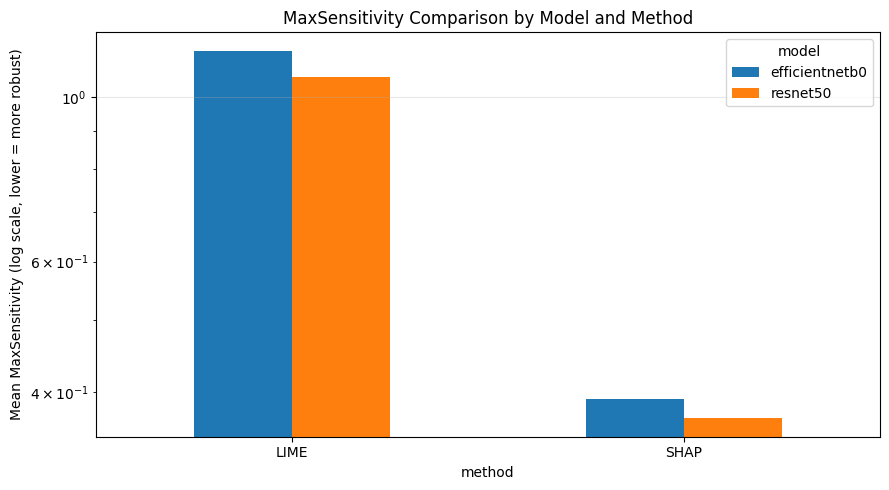

In [ ]:
plt.figure(figsize=(9, 5))
pivot = maxsens_summary.pivot(index='method', columns='model', values='mean_max_sensitivity')
pivot.plot(kind='bar', ax=plt.gca())
plt.yscale("log")
plt.ylabel("Mean MaxSensitivity (log scale, lower = more robust)")
plt.title("MaxSensitivity Comparison by Model and Method")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
